# Bayes features: the generative model's fitted quantities as linear-model regressors

Per run, from each fold's cached Bayes stream posterior (additive rule, 32 draws, no refit): the
ambient level, the slow-wind path, P(arrival by lead), the expected stream excess and their sum,
each a lead-aligned regressor of the submitted linear model. Six yearly folds, official metric.
Not built. Study `python -m training.bayes_features`; write-up `docs/bayes_features.md`.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from training import bayes_features as bf
from training import bayes_stream as tbs
from training import model_diagnostics as dg

d = pd.read_csv(bf.EXPERIMENTS / "bayes_features.csv", dtype={"fold": str})
ref = d[d.variant == "reference"].set_index("fold")
rows = {}
for v, g in d.groupby("variant"):
    g = g.set_index("fold")
    rel = g["all"] / ref["all"]
    rows[v] = {"vs reference %": 100 * (np.exp(np.log(rel).mean()) - 1),
               "folds won": int((rel < 1).sum()),
               **{f"{r} %": 100 * (np.exp(np.log(g[r] / ref[r]).mean()) - 1)
                  for r in dg.RUN_REGIMES}}
pd.DataFrame(rows).T.sort_values("vs reference %").round(2)

,vs reference %,folds won,CME %,stream arrival %,fast stream %,intermediate %,slow wind %
ambient,-0.26,4.0,-0.29,-0.59,0.65,-0.06,-0.50
forward,-0.26,4.0,-0.29,-0.59,0.65,-0.06,-0.50
parr,-0.08,3.0,-0.46,-0.34,-0.43,0.45,1.41
mean,-0.07,3.0,-0.05,-0.13,-0.05,-0.14,0.01
reference,0.00,0.0,0.00,0.00,0.00,0.00,0.00
stream,0.01,3.0,-0.29,-0.16,-0.49,0.35,1.50
components,0.18,3.0,-0.48,-0.41,1.83,0.33,2.19
slow + parr,0.23,3.0,-0.35,-0.06,0.66,0.26,2.23
slow,0.33,2.0,0.20,0.16,1.18,-0.06,0.97


## Per fold: S_final against the submitted model

variant,ambient,components,forward,mean,parr,slow,slow + parr,stream
fold,,,,,,,,
2019,-0.99,-3.02,-0.99,-0.23,-3.40,1.32,-2.08,-3.32
2020,-0.95,-2.21,-0.95,-0.30,-1.72,0.39,-1.42,-1.71
2021,0.37,1.51,0.37,-0.05,0.60,0.27,0.76,0.75
2022,-0.07,4.30,-0.07,0.08,3.82,0.25,4.16,3.87
2023,0.48,-0.51,0.48,0.09,-0.68,-0.04,-0.83,-1.00
2024,-0.42,1.18,-0.42,0.02,1.07,-0.19,0.93,1.61


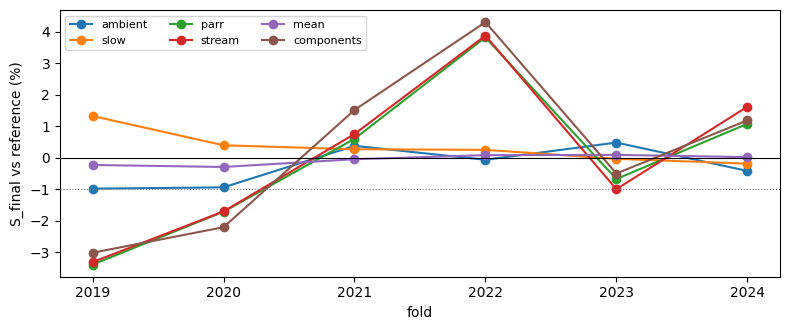

In [2]:
wide = d.pivot(index="fold", columns="variant", values="all")
pct = (wide.div(wide["reference"], axis=0) - 1) * 100
fig, ax = plt.subplots(figsize=(8, 3.4))
for v in ["ambient", "slow", "parr", "stream", "mean", "components"]:
    ax.plot(pct.index, pct[v], marker="o", label=v)
ax.axhline(0, color="k", lw=0.8)
ax.axhline(-1, color="grey", ls=":", lw=0.8)
ax.set_ylabel("S_final vs reference (%)")
ax.set_xlabel("fold")
ax.legend(fontsize=8, ncol=3)
plt.tight_layout()
pct.drop(columns=["reference"]).round(2)

## The features on the 2024 validation runs

Recomputed from the cached 2024 posterior, by run regime: the mean of each feature by lead.

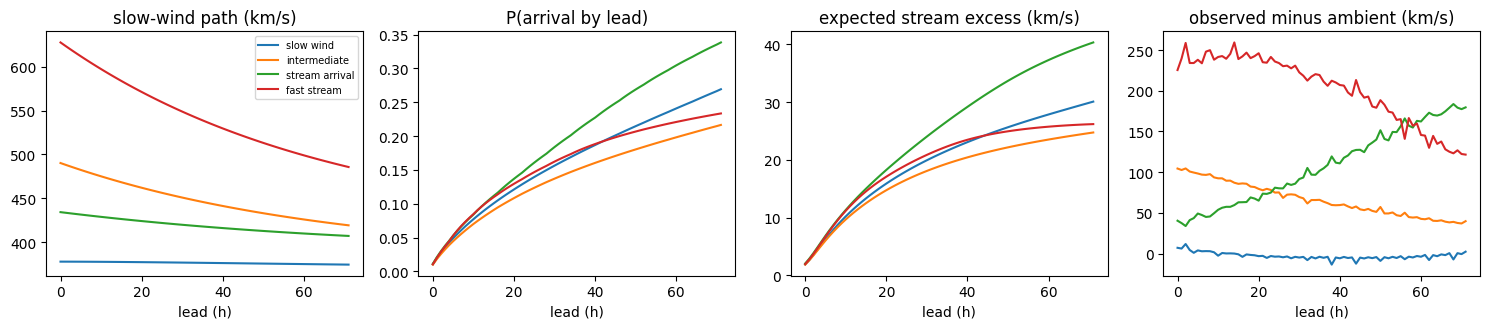

In [3]:
data = dg.Data()
start, end = next((a, b) for a, b in tbs.YEARLY if a.year == 2024)
parts = bf.fold_parts(data, start, end)
z = np.load(tbs.CACHE_DIR / "2024_parts.npz")
model = parts["ff"]["model"]
inp = model.prepare(data.values, data.series.index.get_indexer(parts["val"]), parts["x_val"])
feats = bf.features_in_blocks(dict(np.load(tbs.CACHE_DIR / "2024_observed_draws.npz")), inp,
                              tbs.FITS["observed"])
regime = parts["regime"]
fig, axes = plt.subplots(1, 4, figsize=(15, 3.4))
for r in ("slow wind", "intermediate", "stream arrival", "fast stream"):
    m = regime == r
    axes[0].plot(feats["slow"][m].mean(0), label=r)
    axes[1].plot(feats["parr"][m].mean(0), label=r)
    axes[2].plot(feats["stream"][m].mean(0), label=r)
    axes[3].plot(np.nanmean(parts["obs"][m], 0) - feats["ambient"][m].mean(0), label=r)
for ax, t in zip(axes, ("slow-wind path (km/s)", "P(arrival by lead)",
                        "expected stream excess (km/s)", "observed minus ambient (km/s)"),
                 strict=True):
    ax.set_title(t)
    ax.set_xlabel("lead (h)")
axes[0].legend(fontsize=7)
plt.tight_layout()

## Arrival probability against detected arrivals, 2024

P(arrival within 72 h) from the features, for runs with and without a detected arrival.

AUC 0.685


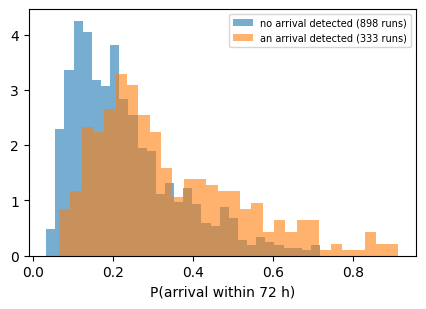

In [4]:
from sklearn.metrics import roc_auc_score

clean = z["m_lab"].all(axis=1)
any_obs = z["n_lab"][clean].sum(axis=1) > 0
p72 = feats["parr"][clean][:, -1]
fig, ax = plt.subplots(figsize=(5, 3.2))
for o in (False, True):
    ax.hist(p72[any_obs == o], bins=30, alpha=0.6, density=True,
            label=f"{'an' if o else 'no'} arrival detected ({(any_obs == o).sum()} runs)")
ax.set_xlabel("P(arrival within 72 h)")
ax.legend(fontsize=7)
print(f"AUC {roc_auc_score(any_obs, p72):.3f}")

## Conclusion

Not built (2026-11-15).
- **Only the ambient level helps, and only a little:** −0.26% against the submitted model, 4 of 6 folds; forward selection adds nothing after it. The rule needs more than 1%.
- **The slow-wind path alone doesn't help** (+0.33%).
- **The stream signals swing with the fold** (`parr` −3.4% on 2019, +3.8% on 2022): better at stream arrivals and fast streams, worse in slow wind, cancelling on average.
- Splitting the generative model's path beats the blended path (`mean`, −0.07%) only through the ambient level.